In [3]:
import os
import random
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import optuna

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.models.wtd_har_gru_wrapper import WTDHARGRUWrapper
from src.eval.scorer import VolatilityScorer
from src.trainer.walk_forward import WalkForwardTrainer

warnings.filterwarnings("ignore")

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

OUT_PATH = PROJECT_ROOT / "data" / "processed"
RESULTS_PATH = PROJECT_ROOT / "results" / "WTD_HAR_GRU"
RESULTS_PATH.mkdir(parents=True, exist_ok=True)

df_train = pd.read_parquet(OUT_PATH / "brent_train.parquet")
y_train = df_train["log_returns"].values.astype("float64")
rs_train = df_train["rs_daily"].values.astype("float64")

df_test = pd.read_parquet(OUT_PATH / "brent_test.parquet")
y_test = df_test["log_returns"].values.astype("float64")
rs_test = df_test["rs_daily"].values.astype("float64")

assert not np.isnan(y_train).any() and not np.isnan(rs_train).any()
assert not np.isnan(y_test).any() and not np.isnan(rs_test).any()

print("=" * 70)
print(f"Train: {len(y_train)} obs  ({df_train.index[0].date()} -> {df_train.index[-1].date()})")
print(f"Test:  {len(y_test)} obs  ({df_test.index[0].date()} -> {df_test.index[-1].date()})")
print("=" * 70)

Train: 2171 obs  (2014-01-03 -> 2022-11-03)
Test:  953 obs  (2022-11-07 -> 2026-08-21)


In [2]:
import time
from src.eval.losses import QLIKELoss

scorer = VolatilityScorer()

model = WTDHARGRUWrapper(
    look_back=14,
    hidden_size=16,
    num_layers=1,
    dropout=0.1,
    learning_rate=1e-3,
    weight_decay=1e-6,
    max_epochs=30,
    patience=5,
    batch_size=128,
    retrain_freq=10_000,
    target_scale=1e4,    
)

print(">> Iniciando fit del WTD-HAR-GRU ...")
t0 = time.time()
# Usamos los primeros 1000 datos para que vuele
model.fit(y_train[:1000], rs_train[:1000])
print(f">> Fit OK en {time.time() - t0:.1f} s")
print("   diagnostics:", model.get_diagnostics())

print(">> Iniciando forecast (10 días) ...")
t0 = time.time()
preds = model.forecast(y_test[:10], rs_test[:10])
print(f">> Forecast OK en {time.time() - t0:.1f} s")
print(f"   preds[:5] = {preds[:5]}")
print(f"   rango = [{preds.min():.3e}, {preds.max():.3e}]")

qlike = scorer.qlike(rs_test[:10], preds)
print(f">> QLIKE (10 días): {qlike:.4f}")

>> Iniciando fit del WTD-HAR-GRU ...
>> Fit OK en 23.0 s
   diagnostics: {'converged': True, 'epochs_run': 23}
>> Iniciando forecast (10 días) ...
>> Forecast OK en 0.4 s
   preds[:5] = [0.00020664 0.00015391 0.00015007 0.00020988 0.00014818]
   rango = [1.461e-04, 2.099e-04]
>> QLIKE (10 días): 1.1747


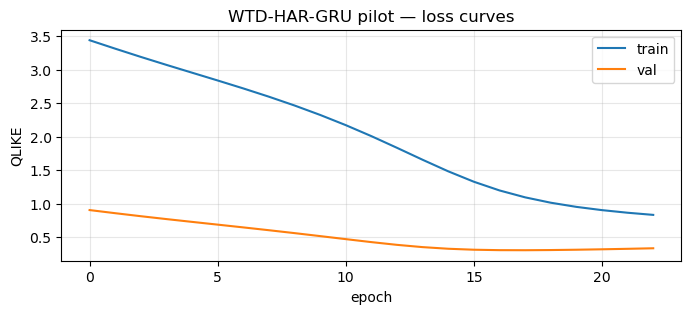

In [3]:
import matplotlib.pyplot as plt

hist = model.get_history()
plt.figure(figsize=(8, 3))
plt.plot(hist["train_loss"], label="train")
plt.plot(hist["val_loss"],   label="val")
plt.xlabel("epoch"); plt.ylabel("QLIKE"); plt.legend(); plt.grid(alpha=0.3)
plt.title("WTD-HAR-GRU pilot — loss curves")
plt.show()

In [6]:
import time

FULL_DIR = RESULTS_PATH / "quick_test"
FULL_DIR.mkdir(parents=True, exist_ok=True)

def wtd_har_gru_search_space_quick(trial: optuna.Trial) -> dict:
    # Parámetros fijos y pequeños para la prueba
    return {
        "look_back": 14,
        "hidden_size": 16,
        "num_layers": 1,
        "dropout": 0.1,
        "learning_rate": 1e-3,
        "weight_decay": 1e-6,
        "max_epochs": 10,
        "patience": 5,
        "retrain_freq": 10,
        "target_scale": 1e4,
        "seed": 42,
    }

print("Iniciando WTD-HAR-GRU | PRUEBA RÁPIDA")

trainer = WalkForwardTrainer(
    model_class=WTDHARGRUWrapper,
    scorer=VolatilityScorer(),
    output_dir=FULL_DIR,
    n_splits=1,
    warmup=800,
    embargo=1,
    suggest_params_fn=wtd_har_gru_search_space_quick,
    n_trials=1,
    early_stop_rounds=None,
)

t0 = time.time()
trainer.run(y_train[:1000], rs_train[:1000])
print(f"Tiempo total: {(time.time() - t0) / 60:.2f} min")

Iniciando WTD-HAR-GRU | PRUEBA RÁPIDA
Tiempo total: 0.07 min


# ENTRENAMIENTO

In [7]:
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true" 

FULL_DIR = RESULTS_PATH / "wtd_har_gru_full_run" 
FULL_DIR.mkdir(parents=True, exist_ok=True)

def wtd_har_gru_search_space(trial: optuna.Trial) -> dict:
    return {
        "lag_weekly": trial.suggest_categorical("lag_weekly", [5, 7]),
        "lag_monthly": trial.suggest_categorical("lag_monthly", [22, 30]),
        "look_back": trial.suggest_categorical("look_back", [7, 14, 21, 28]),
        "hidden_size": trial.suggest_categorical("hidden_size", [32, 64, 128]), 
        "num_layers": trial.suggest_int("num_layers", 1, 2),
        "dropout": trial.suggest_float("dropout", 0.0, 0.3),                    
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True), 
        "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-3, log=True),
        "max_epochs": 200,
        "patience": 20,
        "retrain_freq": 1,
        "target_scale": 1e4, 
        "seed": 42
    }

current_warmup = 1210
print(f"Iniciando WTD-HAR-GRU | Ejecución Única | warmup={current_warmup}")

trainer = WalkForwardTrainer(
    model_class=WTDHARGRUWrapper,
    scorer=VolatilityScorer(),
    output_dir=FULL_DIR,
    n_splits=5,
    warmup=current_warmup,
    embargo=1,
    suggest_params_fn=wtd_har_gru_search_space,
    n_trials=50,
    early_stop_rounds=15
)

t0 = time.time()
trainer.run(y_train, rs_train)
print(f"Tiempo total: {(time.time() - t0) / 60:.1f} min")

Iniciando WTD-HAR-GRU | Ejecución Única | warmup=1210


  0%|          | 0/50 [00:00<?, ?it/s]

[W 2026-11-04 23:16:09,483] Trial 0 failed with parameters: {'lag_weekly': 5, 'lag_monthly': 30, 'look_back': 14, 'hidden_size': 32, 'num_layers': 2, 'dropout': 0.08624107671207985, 'learning_rate': 0.0006891269117006192, 'weight_decay': 1.35694533114613e-06} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "C:\Users\jcami\.conda\envs\brent-dl\lib\site-packages\optuna\study\_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "C:\Users\jcami\Documents\brent-crude-nlp-market-dynamics\src\trainer\walk_forward.py", line 239, in <lambda>
    lambda trial: self.objective(trial, y, rs),
  File "C:\Users\jcami\Documents\brent-crude-nlp-market-dynamics\src\trainer\walk_forward.py", line 142, in objective
    model.fit(y_train, rs_train)
  File "C:\Users\jcami\Documents\brent-crude-nlp-market-dynamics\src\models\wtd_har_gru_wrapper.py", line 148, in fit
    X, har_preds, har_resids = self._build_3channel_data(y_train, rs_t

KeyboardInterrupt: 